# DS1 1q parameters over time

## Overview
C1 showed how the DS3 KPIs move, and now we ask the same of the 1q parameters calibrate_1q applies - qubit frequency, drive amplitude, DRAG and frequency shift amplitude ([Phase 01, C2](../../docs/phases/01_eda.md#c2-1q-parameters-over-time)). We build on [B3c](../01_profiling/b3c_ds1_noise_1q.ipynb)'s noise rows and reuse C1's methods from the shared [analysis package](../../src/qpu_drift/analysis/__init__.py).

**Question.** How do the applied 1q parameters change beyond their noise, and on what timescale?

**Method.** We build the series and take out a time-of-day level (section 1), then scan the signal ratio over lags for each param's timescale and block length (section 2). Next we check whether qubits move together and test drift on a chip-wide series (section 3), test steps at the breaks against a placebo and find the run where each one happens (section 4), and look for change points, refitting the drift between them (section 5).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qpu_drift import periods
from qpu_drift.analysis import methods, series
from qpu_drift.analysis.constants import KOLMOGOROV_95, MIN_N, NEAR_EVENT, SIGNAL_MIN
from qpu_drift.derived.noise import load_noise_floor
from qpu_drift.derived.run_map import load_run_entities, load_run_map, load_run_results
from qpu_drift.paths import REPO_ROOT
from qpu_drift.sources.measurements import load_measurements

pd.set_option("display.max_rows", 300, "display.max_columns", 40, "display.width", 250, "display.max_colwidth", 100)
FIG = REPO_ROOT / "docs" / "figures" / "eda"
FIG.mkdir(parents=True, exist_ok=True)

LAGS = [1, 2, 3, 4, 7, 14, 28]  # as C1, in calibrate_1q runs
K_MIN = 7  # shortest step window and change-point segment, in runs (as C1)
MIN_UNITS = 5  # qubits needed for a chip-wide value (all of them where the param has fewer)
PARAMS = ["freq", "amp_x_scale", "drag", "freq_shift_amp"]
SER = ["param", "qubit", "stratum"]
INCIDENT_STARTS = [i.period[0] for i in periods.INCIDENTS]
EV = series.register_events()
order = lambda i: i.map(series.stratum_order) if i.name == "stratum" else i
print(f"signal ratio for signal {SIGNAL_MIN}+; pairs per series-lag {MIN_N}+; events within {NEAR_EVENT}; CUSUM critical value {KOLMOGOROV_95}")

nz = series.ds1_1q_noise(load_noise_floor())
print("B3c noise rows (param, qubit, stratum) per main method:",
      nz.groupby([nz.index.get_level_values("param"), "main_method"]).size().to_dict())
runs1q = load_run_map(routine="calibrate_1q")
rows = series.onevq_rows(load_run_entities(routine="calibrate_1q"), runs1q)
ax = series.amp_x_scale(rows, series.drive_scale())
fs = series.freq_shift_rows(load_measurements(), load_run_results())
run_of = pd.Series(np.arange(runs1q["start"].nunique()), index=np.sort(runs1q["start"].unique()))
fs = fs.assign(param="freq_shift_amp", run=fs["start"].map(run_of), t=fs["start"], value=fs["new"],
               incident=periods.within(fs["start"], *[i.period for i in periods.INCIDENTS]),
               f01_flag=periods.f01_flagged(fs["start"], fs["qubit"]), stratum=series.stratum_label(fs["start"]))
print("calibrate_1q runs:", len(runs1q), "| applied rows per param:", rows.groupby("param").size().to_dict(),
      "| amp_x_scale rows:", len(ax), "| freq_shift rows:", len(fs), "per qubit", fs.groupby("qubit").size().to_dict())
print("freq_shift rows: sd not finite or <= 0:", int((~np.isfinite(fs["sd"]) | (fs["sd"] <= 0)).sum()),
      "; new equal to old:", int((fs["new"] == fs["old"]).sum()), "; start not in the run map:", int(fs["run"].isna().sum()))

signal ratio for signal 2.0+; pairs per series-lag 20+; events within 2 days 00:00:00; CUSUM critical value 1.358
B3c noise rows (param, qubit, stratum) per main method: {('amp', 'final_step_fit_sd_median_x_rsd_zc'): 207, ('amp_x_scale', 'final_step_fit_sd_over_abs_new_median_x_rsd_zc'): 207, ('drag', 'final_step_fit_sd_median_x_rsd_zc'): 205, ('freq', 'final_step_fit_sd_median_x_rsd_zc'): 203, ('freq_shift_amp', 'final_step_fit_sd_median'): 15}


calibrate_1q runs: 1298 | applied rows per param: {'amp': 39393, 'drag': 36721, 'freq': 37882} | amp_x_scale rows: 34134 | freq_shift rows: 2675 per qubit {2: 1243, 13: 1241, 23: 191}
freq_shift rows: sd not finite or <= 0: 0 ; new equal to old: 0 ; start not in the run map: 0


## 1. Series and checks

We take the values each calibrate_1q run applied (`series.onevq_rows`), for the params the run changed. freq (Hz) and drag go in as written. amp only means something together with the DS2 drive scale $s$ - the pulse the qubit sees scales with their product - so we use $\ln|\text{amp} \times s|$, with $s$ at the run's `snap_after` (`series.amp_x_scale`). freq_shift_amp comes from the FineFreqShift payloads (`series.freq_shift_rows`), keeping rows with a finite sd and a new value. Rows inside `INCIDENTS` or the f01 flags are left out, and a series is one param, qubit and stratum.

Each series takes its B3c noise row (`series.ds1_1q_noise`). The fit sd misses part of the within-run scatter, so a signal ratio against it runs high, and B3c reads signal off the centred scaled σ instead. We do the same: it's our main σ, with the fit sd as the high end. For amp_x_scale both are the amp σ over |amp|, so they're in ln units, and freq_shift_amp only has the fit sd. Series without a noise row drop out here.

In [2]:
cols = ["param", "qubit", "stratum", "run", "t", "value", "incident", "f01_flag"]
fs_ok = fs[np.isfinite(fs["sd"]) & (fs["sd"] > 0) & (fs["new"] != fs["old"]) & fs["run"].notna()]
allr = pd.concat([rows.loc[rows["param"].isin(["freq", "drag"]), cols], ax[cols + ["amp", "scale"]], fs_ok[cols]],
                 ignore_index=True)
allr["run"] = allr["run"].astype(int)
drop = allr["incident"] | allr["f01_flag"]
print("rows left out (incident or f01 flag) per param:", allr[drop].groupby("param").size().to_dict())
d = allr[~drop].copy()
d = d.join(nz[["sigma_main", "sigma"]].rename(columns={"sigma": "sigma_fit"}), on=SER)
d["y"] = d["value"]
sers = d.groupby(SER).agg(n=("run", "size"), start=("t", "min"), end=("t", "max"), sigma_main=("sigma_main", "first"),
                          sigma_fit=("sigma_fit", "first"))
sers["has_noise"] = sers["sigma_main"].notna()
print("series and rows, and those with a noise row, per param:")
display(sers.groupby(level="param").agg(series=("n", "size"), rows=("n", "sum"), with_noise=("has_noise", "sum"),
                                        rows_with_noise=("n", lambda s: int(s[sers.loc[s.index, "has_noise"]].sum())),
                                        qubits=("n", lambda s: s.index.get_level_values("qubit").nunique())).reindex(PARAMS))
print("series with a noise row per stratum:")
display(sers[sers["has_noise"]].reset_index().pivot_table(index="stratum", columns="param", values="n", aggfunc="size")
        .reindex(columns=PARAMS).sort_index(key=lambda i: i.map(series.stratum_order)).fillna(0).astype(int))
print("main sigma over the fit sd per series, median and range per param:")
display((sers["sigma_main"] / sers["sigma_fit"]).groupby(level="param").describe()[["count", "min", "50%", "max"]]
        .reindex(PARAMS).round(3))
a = d[d["param"] == "amp_x_scale"].sort_values("run")
chg = a.groupby("qubit")["scale"].diff().ne(0) & a.groupby("qubit").cumcount().gt(0)
print(f"amp_x_scale: consecutive rows of a qubit where the drive scale differs: {int(chg.sum())} of {int(a.groupby('qubit').cumcount().gt(0).sum())}")
d = d[d["sigma_main"].notna()].copy()

rows left out (incident or f01 flag) per param: {'amp_x_scale': 200, 'drag': 197, 'freq': 315, 'freq_shift_amp': 22}
series and rows, and those with a noise row, per param:


,series,rows,with_noise,rows_with_noise,qubits
param,,,,,
freq,392,37567,203,34010,33
amp_x_scale,384,33934,207,30687,32
drag,390,36524,205,34036,33
freq_shift_amp,25,2653,15,2543,3


series with a noise row per stratum:


param,freq,amp_x_scale,drag,freq_shift_amp
stratum,,,,
2 (2024-09-18),29,31,29,3
4 (2025-02-17),29,23,29,2
7 (2025-03-28),29,31,29,2
8 (2025-07-07),29,31,29,2
9 (2025-08-22),29,31,29,2
11 (2026-03-24),29,30,30,2
13 (2026-05-25),29,30,30,2


main sigma over the fit sd per series, median and range per param:


,count,min,50%,max
param,,,,
freq,203.0,1.414,1.463,1.802
amp_x_scale,207.0,0.993,1.188,1.302
drag,205.0,0.956,1.016,1.234
freq_shift_amp,15.0,1.000,1.000,1.000


amp_x_scale: consecutive rows of a qubit where the drive scale differs: 33901 of 33902


**Results.**

- There are 1,298 calibrate_1q runs. With a noise row we have 203 freq, 207 amp_x_scale, 205 drag and 15 freq_shift_amp series, from 29 to 31 qubits per stratum (23 for amp_x_scale in stratum 4) and 2 or 3 for freq_shift_amp.
- The main σ is a median 1.46 times the fit sd for freq, 1.19 for amp_x_scale and 1.02 for drag, so the choice matters most for freq.
- The drive scale changes between 33,901 of 33,902 consecutive amp rows of a qubit, so amp on its own isn't the applied drive.

calibrate_1q runs about twice a day, at around 08:00 and 19:00 UTC, so a lag-1 pair almost always joins a morning and an evening run. If a param sits at a different level in the evening, that inflates the lag-1 ratio and makes the series zigzag. With $d$ the lag-1 step, the evening offset is

$$\Delta_\text{eve} = \tfrac12\left(\operatorname{median} d_{m \to e} - \operatorname{median} d_{e \to m}\right),$$

where a slow drift adds the same to both terms and cancels. We then recompute the lag-1 ratio with $\Delta_\text{eve}$ taken off the mixed pairs.

In [3]:
print("calibrate_1q rows by start hour (UTC):", d["t"].dt.hour.value_counts().sort_index().to_dict())
AM_END = 14  # rows starting before 14:00 UTC are 'morning'
d["evening"] = d["t"].dt.hour >= AM_END
tod = []
for p in ["freq", "amp_x_scale", "drag"]:
    lp = methods.lag_pairs(d[d["param"] == p], SER, 1, col="y", cuts=INCIDENT_STARTS)
    ev0, ev1 = lp["t_0"].dt.hour >= AM_END, lp["t_1"].dt.hour >= AM_END
    lp["kind"] = np.select([~ev0 & ev1, ev0 & ~ev1], ["m_e", "e_m"], "same")
    for key, g in lp.groupby(SER):
        me, em = g.loc[g["kind"] == "m_e", "d"], g.loc[g["kind"] == "e_m", "d"]
        if len(g) < MIN_N or min(len(me), len(em)) < 10:
            continue
        off = (me.median() - em.median()) / 2  # evening minus morning level; a slow drift adds to both and cancels
        adj = g["d"] - np.select([g["kind"] == "m_e", g["kind"] == "e_m"], [off, -off], 0.0)
        sig = sers.loc[key, "sigma_main"]
        tod.append(dict(zip(SER, key)) | {"pairs": len(g), "share_mixed": (g["kind"] != "same").mean(), "offset": off,
                                          "offset_sigma": off / sig, "ratio_lag1": (methods.rsd(g["d"]) / np.sqrt(2) / sig) ** 2,
                                          "ratio_lag1_offset_removed": (methods.rsd(adj) / np.sqrt(2) / sig) ** 2})
tod = pd.DataFrame(tod)
print("time-of-day level per series (20+ lag-1 pairs, 10+ each of morning -> evening and evening -> morning): offset =",
      "(median lag-1 step morning -> evening - median evening -> morning) / 2, native and in the series' main sigma;",
      "lag-1 signal ratio before and after taking it off the mixed pairs:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(tod.groupby("param").agg(series=("pairs", "size"), share_mixed_pairs=("share_mixed", "median"),
                                     offset=("offset", "median"), offset_sigma=("offset_sigma", "median"),
                                     abs_offset_sigma=("offset_sigma", lambda s: s.abs().median()),
                                     share_offset_pos=("offset_sigma", lambda s: (s > 0).mean()), ratio_lag1=("ratio_lag1", "median"),
                                     ratio_lag1_offset_removed=("ratio_lag1_offset_removed", "median")).reindex(PARAMS).dropna(how="all"))
off = tod[tod["param"] == "amp_x_scale"].set_index(SER)["offset"]
row_off = off.reindex(pd.MultiIndex.from_frame(d[SER])).fillna(0).to_numpy()
isax = (d["param"] == "amp_x_scale").to_numpy()
d["y"] = d["y"] - np.where(d["evening"].to_numpy() & isax, row_off, 0.0)
print(f"amp_x_scale: series with an offset {off.size} of {d.loc[isax, SER].drop_duplicates().shape[0]};",
      f"evening rows shifted {int((d['evening'].to_numpy() & isax & (row_off != 0)).sum())} of {int(isax.sum())} rows")

calibrate_1q rows by start hour (UTC): {0: 148, 1: 76, 2: 61, 3: 61, 4: 61, 7: 546, 8: 49428, 11: 61, 12: 213, 13: 470, 15: 152, 16: 311, 17: 61, 18: 2074, 19: 45416, 20: 1267, 21: 567, 22: 181, 23: 122}


time-of-day level per series (20+ lag-1 pairs, 10+ each of morning -> evening and evening -> morning): offset = (median lag-1 step morning -> evening - median evening -> morning) / 2, native and in the series' main sigma; lag-1 signal ratio before and after taking it off the mixed pairs:


,series,share_mixed_pairs,offset,offset_sigma,abs_offset_sigma,share_offset_pos,ratio_lag1,ratio_lag1_offset_removed
param,,,,,,,,
freq,203,0.966,135,0.0277,0.161,0.547,1.34,1.32
amp_x_scale,207,0.989,-0.000669,-3.86,3.86,0.00483,44,23.9
drag,205,0.966,1.53e-13,0.0134,0.193,0.512,1.93,1.88


amp_x_scale: series with an offset 207 of 207; evening rows shifted 15210 of 30687 rows


**Results.**

- amp_x_scale sits lower in the evening: a median −3.86 σ, with only 1 of 207 series above the morning level. Taking it off about halves the lag-1 ratio, from 44.0 to 23.9.
- freq and drag show no such level - a median 0.03 and 0.01 σ, with the signs split evenly - and their lag-1 ratio barely moves.

So from here on amp_x_scale's evening rows are shifted to the morning level (15,210 of 30,687 rows), and freq and drag stay as they are.

## 2. Timescales

As in C1 section 2, $\sigma_L$ is the robust sd of differences $L$ runs apart, over $\sqrt 2$ (`methods.structure_function`), and the signal ratio is

$$S_L = \left(\frac{\sigma_L}{\sigma_n}\right)^2.$$

Lags count calibrate_1q runs, about half a day apart, and a run that didn't change a param has no row for it. $L^*$ is a series' first lag with $S_L \ge 2$, and only series with one go into the per-qubit tests. On the balanced set - series with 20+ pairs at every lag - $L_\text{var}$ is the first lag where the median $S_L$ reaches 2, and the block length comes from the variance ratio $V_L = (\sigma_L / \sigma_1)^2$ (`methods.block_length`). A block of 28 means no plateau, and sends a param to the jump scan in section 5.

We compute $S_L$ against both σ, to see how much hangs on the choice.

In [4]:
sf = methods.structure_function(d, SER, LAGS, col="y", cuts=INCIDENT_STARTS)
sf = sf.join(sers[["sigma_main", "sigma_fit"]])
sf["ratio"] = (sf["sigma"] / sf["sigma_main"]) ** 2
sf["ratio_fit"] = (sf["sigma"] / sf["sigma_fit"]) ** 2
sf = sf.join(sf.xs(1, level="lag")["sigma"].rename("sigma_1"))
sf["var_ratio"] = (sf["sigma"] / sf["sigma_1"]) ** 2


def first_lag(col: str) -> pd.Series:
    """Per series, the smallest lag whose ratio in col reaches SIGNAL_MIN (NaN if none up to 28)."""
    w = sf[col].unstack("lag").ge(SIGNAL_MIN)
    return pd.Series(np.where(w.any(axis=1), w.idxmax(axis=1), np.nan), index=w.index)


lstar, lstar_fit = first_lag("ratio"), first_lag("ratio_fit")
sers = sers.join(lstar.rename("lstar"))
n_ser = sf.xs(1, level="lag").groupby(level="param").size()
tab = pd.concat({name: l.groupby(level="param").value_counts().unstack().reindex(index=PARAMS, columns=LAGS).fillna(0).astype(int)
                 .assign(none=lambda x: n_ser.reindex(PARAMS) - x.sum(axis=1))
                 for name, l in {"main": lstar, "fit sd": lstar_fit}.items()})
print("series by L* (smallest lag, in runs, with signal ratio >= 2; none up to 28), against the main sigma and the fit sd:")
display(tab)

# L_var, the block and the timescale fit use the same series at every lag, so the curve is not a change of series
agg = dict(series=("ratio", "size"), ratio_median=("ratio", "median"), share_ge_2=("ratio", lambda s: (s >= SIGNAL_MIN).mean()),
           ratio_fit_median=("ratio_fit", "median"), var_ratio_median=("var_ratio", "median"), days_median=("days", "median"))
full = sf["sigma"].unstack("lag").notna().all(axis=1)
sfb = sf[full.reindex(sf.index.droplevel("lag")).to_numpy()]
pool_b = sfb.groupby(["param", "lag"]).agg(**agg)
print("balanced set (series with 20+ pairs at every lag):", full.groupby(level="param").sum().to_dict(), "of",
      full.groupby(level="param").size().to_dict())
with pd.option_context("display.float_format", "{:.3g}".format):
    display(pool_b.unstack("param").swaplevel(axis=1).sort_index(axis=1).reindex(columns=PARAMS, level=0))
lvar = {p: next((L for L, v in g.droplevel("param").items() if v >= SIGNAL_MIN), np.nan)
        for p, g in pool_b["ratio_median"].groupby(level="param")}
lvar_fit = {p: next((L for L, v in g.droplevel("param").items() if v >= SIGNAL_MIN), np.nan)
            for p, g in pool_b["ratio_fit_median"].groupby(level="param")}
vr_all = sfb.groupby(["param", "lag"])["var_ratio"].median()
block = {p: methods.block_length(vr_all.xs(p)) for p in PARAMS}
plateau = {p: block[p] < max(LAGS) for p in PARAMS}
print("L_var (smallest lag with median signal ratio >= 2 over the balanced set, runs): main", lvar, "| fit sd", lvar_fit)
print("block length (runs), variance ratio over the balanced set:", block)
print("variance ratio levels off within the lags (change points by CUSUM; else by the jump scan):", plateau)

series by L* (smallest lag, in runs, with signal ratio >= 2; none up to 28), against the main sigma and the fit sd:


1   2   3  4   7  14  28  none
       param                                           
main   freq             60  15  12  7  10  19  19    61
       amp_x_scale     207   0   0  0   0   0   0     0
       drag            100  18  11  5   3   4   4    60
       freq_shift_amp    8   0   2  1   0   1   0     3
fit sd freq            155  21   3  4   3   3   1    13
       amp_x_scale     207   0   0  0   0   0   0     0
       drag            105  13  15  4   3   4   6    55
       freq_shift_amp    8   0   2  1   0   1   0     3

balanced set (series with 20+ pairs at every lag): {'amp_x_scale': 183, 'drag': 176, 'freq': 174, 'freq_shift_amp': 13} of {'amp_x_scale': 207, 'drag': 205, 'freq': 203, 'freq_shift_amp': 15}


param        freq                                                                  amp_x_scale                                                                         drag                                                                   \
      days_median ratio_fit_median ratio_median series share_ge_2 var_ratio_median days_median ratio_fit_median ratio_median series share_ge_2 var_ratio_median days_median ratio_fit_median ratio_median series share_ge_2 var_ratio_median   
lag                                                                                                                                                                                                                                            
1           0.495             3.18         1.33    174      0.287                1         0.5               39         26.9    183          1                1       0.499             2.22         1.99    176        0.5                1   
2               1             3.52          1.4    174      0.356             1.16           1             47.6         32.1    183          1             1.25           1             2.33         2.12    176      0.534             1.14   
3             1.5             3.89         1.58    174      0.402              1.3         1.5             85.2         57.3    183          1             2.18        1.51             2.59         2.23    176      0.562             1.17   
4               2             3.84         1.62    174      0.408             1.31           2             99.6         69.6    183          1             2.58           2             2.71         2.37    176      0.562             1.18   
7            3.52             4.51         1.88    174      0.477             1.46        3.54              196          139    183          1             4.19        3.54             2.83         2.44    176      0.574             1.21   
14              7             5.75         2.47    174      0.603             1.84           7              223          154    183          1             4.01           7             2.77          2.5    176      0.585             1.22   
28             14             8.07         3.32    174      0.701             2.42          14              236          165    183          1             4.09          14             2.85          2.5    176      0.597             1.32   

param freq_shift_amp                                                                   
         days_median ratio_fit_median ratio_median series share_ge_2 var_ratio_median  
lag                                                                                    
1                0.5              2.9          2.9     13      0.538                1  
2                  1             3.16         3.16     13      0.538              1.2  
3                1.5             5.34         5.34     13      0.692             1.84  
4                  2             4.96         4.96     13      0.692             1.97  
7               3.51             4.49         4.49     13      0.769             2.62  
14                 7             5.28         5.28     13      0.846              3.6  
28                14             6.57         6.57     13      0.769             4.88

L_var (smallest lag with median signal ratio >= 2 over the balanced set, runs): main {'amp_x_scale': 1, 'drag': 2, 'freq': 14, 'freq_shift_amp': 1} | fit sd {'amp_x_scale': 1, 'drag': 1, 'freq': 1, 'freq_shift_amp': 1}
block length (runs), variance ratio over the balanced set: {'freq': 28, 'amp_x_scale': 7, 'drag': 7, 'freq_shift_amp': 28}
variance ratio levels off within the lags (change points by CUSUM; else by the jump scan): {'freq': False, 'amp_x_scale': True, 'drag': True, 'freq_shift_amp': False}


**Results.**

- Against the main σ, $L^*$ is lag 1 for all 207 amp_x_scale series, 100 of 205 drag and only 60 of 203 freq, and 61 freq and 60 drag series never reach 2 up to lag 28. Against the fit sd, freq has 155 at lag 1 and only 13 that never get there - so for freq, whether a run-to-run change counts as signal depends on the σ.
- On the balanced set $L_\text{var}$ is 1 run for amp_x_scale and freq_shift_amp, 2 for drag and 14 for freq. Against the fit sd it's 1 for every param.
- The block is 7 runs for amp_x_scale and drag, and 28 for freq and freq_shift_amp, which get the jump scan.

As in C1, we fit the balanced median curve with

$$S_L = c + a\left(1 - e^{-L/\tau}\right), \qquad c, a \ge 0$$

(`methods.fit_timescale`), plus a random walk $c + bL$ and a constant, and keep the lowest AICc. $c$ is the part that's new at every run - 1 if the σ were right and nothing else changed - while $a$ and $\tau$ are the size and length, in runs, of a correlated part.

timescale fit of the balanced median signal ratio against lag, per param (c, a in noise units; tau in runs and days); random walk c + b L; best: lowest AICc of exponential, random walk and constant:


,points,c,a,tau,sse,tau_at_edge,rw_c,rw_b,rw_sse,flat_sse,aicc,rw_aicc,flat_aicc,best,days_per_run,tau_days
freq,7,1.23,4.03,38.3,0.00408,False,1.32,0.0737,0.0302,3.08,-38.1,-31.1,-2.95,exp,0.5,19.1
amp_x_scale,7,0,173,6.4,1e+03,False,49.1,5.09,6.37e+03,2.09e+04,48.7,54.7,58.8,exp,0.5,3.2
drag,7,1.73,0.771,2.67,0.00273,False,2.18,0.015,0.115,0.241,-41,-21.7,-20.8,exp,0.5,1.34
freq_shift_amp,7,1.59,4.14,2.67,3.08,False,3.79,0.105,3.82,9.97,8.26,2.75,5.27,rw,0.5,1.34


per-series fits (series with a signal ratio at 5+ lags): medians, share with tau at the grid edge, and share per best model by AICc:


,series,c,a,tau_runs,tau_at_edge,best_exp,best_flat,best_rw
param,,,,,,,,
freq,203,0.778,6.54,17.4,0.36,0.0887,0.365,0.547
amp_x_scale,207,0,195,5.77,0.14,0.28,0.415,0.304
drag,205,1.08,2.47,2.41,0.239,0.0732,0.649,0.278
freq_shift_amp,15,0.471,4.68,5.31,0,0.4,0.2,0.4


saved docs/figures/eda/c2_structure_function.png
rows per param for per-qubit analyses (series with an L*): {'amp_x_scale': 30687, 'drag': 22054, 'freq': 23645, 'freq_shift_amp': 2138}


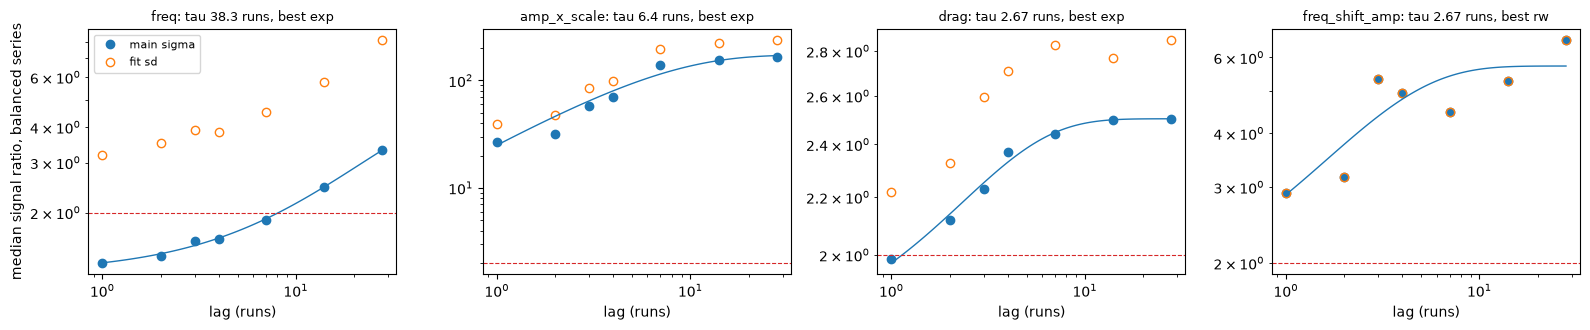

In [5]:
fits = pd.DataFrame({p: methods.fit_timescale(g.index.get_level_values("lag"), g["ratio_median"].to_numpy())
                     for p, g in pool_b.groupby(level="param")}).T
fits["days_per_run"] = (pool_b["days_median"] / pool_b.index.get_level_values("lag")).groupby(level="param").median()
fits["tau_days"] = fits["tau"].astype(float) * fits["days_per_run"]
print("timescale fit of the balanced median signal ratio against lag, per param (c, a in noise units; tau in runs and days);",
      "random walk c + b L; best: lowest AICc of exponential, random walk and constant:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(fits.reindex(PARAMS))
per = []
for key, g in sf["ratio"].dropna().groupby(level=SER):
    if len(g) >= 5:
        per.append(dict(zip(SER, key)) | methods.fit_timescale(g.index.get_level_values("lag"), g.to_numpy()))
per = pd.DataFrame(per)
print("per-series fits (series with a signal ratio at 5+ lags): medians, share with tau at the grid edge, and share per best model by AICc:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(per.groupby("param").agg(series=("tau", "size"), c=("c", "median"), a=("a", "median"), tau_runs=("tau", "median"),
                                     tau_at_edge=("tau_at_edge", "mean"))
            .join(pd.crosstab(per["param"], per["best"], normalize="index").add_prefix("best_")).reindex(PARAMS))

fig, axes = plt.subplots(1, len(PARAMS), figsize=(16, 3.4))
Lg = np.geomspace(1, 28, 100)
for axx, p in zip(axes, PARAMS):
    g = pool_b.xs(p)
    axx.plot(g.index, g["ratio_median"], "o", color="C0", label="main sigma")
    axx.plot(g.index, g["ratio_fit_median"], "o", mfc="none", color="C1", label="fit sd")
    f = fits.loc[p]
    axx.plot(Lg, f["c"] + f["a"] * (1 - np.exp(-Lg / f["tau"])), color="C0", lw=1)
    axx.axhline(SIGNAL_MIN, color="C3", lw=0.8, ls="--")
    axx.set_xscale("log")
    axx.set_yscale("log")
    axx.set_title(f"{p}: tau {f['tau']:.3g} runs, best {f['best']}", fontsize=9)
    axx.set_xlabel("lag (runs)")
axes[0].set_ylabel("median signal ratio, balanced series")
axes[0].legend(fontsize=8)
fig.tight_layout()
out = FIG / "c2_structure_function.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

d = d.join(sers["lstar"], on=SER)
d["block"] = d["param"].map(block)
d["scan"] = ~d["param"].map(plateau)
d["min_seg"] = np.maximum(K_MIN, d["lstar"].fillna(K_MIN)).astype(int)
print("rows per param for per-qubit analyses (series with an L*):", d[d["lstar"].notna()].groupby("param").size().to_dict())

**Results.**

- An exponential fits best for freq ($\tau$ 38.3 runs, 19.1 days), amp_x_scale (6.4 runs, 3.2 days) and drag (2.67 runs, 1.34 days), and a random walk for freq_shift_amp. No $\tau$ is at the grid edge.
- freq's $c$ is 1.23, so against the main σ it barely moves from one run to the next, and its change builds up over weeks ($a$ 4.03). drag has a little extra scatter ($c$ 1.73) and a small, fast correlated part ($a$ 0.77). amp_x_scale is far above its noise at every lag ($a$ 173).
- Per series it's noisier: a random walk or a constant beats the exponential on most freq and drag series, and freq's $\tau$ is at the grid edge on 0.36 of them.

## 3. Common mode and drift within strata

Before testing drift, we check whether qubits move together, as in C1 section 3. Per param and stratum the chip-wide series is the median over qubits of the value centred per series, on runs with 5+ qubits (all 3 for freq_shift_amp), and its spread against the qubits' own is

$$s = \left(\frac{\operatorname{rsd}(\text{chip-wide series})}{\operatorname{median}\ \operatorname{rsd}(\text{centred series})}\right)^2.$$

Unrelated qubits give $s \approx \pi / 2N$, so the null shifts each qubit's series circularly by a random offset (200 draws, `methods.common_mode_share`).

In [6]:
nq = d.groupby("param")["qubit"].nunique()
need = {p: int(min(MIN_UNITS, nq.get(p, 0))) for p in PARAMS}
print("qubits needed for a chip-wide value:", need)
dc = d.assign(yc=d["y"] - d.groupby(SER)["y"].transform("median"))
chip = dc.groupby(["param", "stratum", "run"]).agg(t=("t", "min"), y=("yc", "median"), units=("qubit", "nunique")).reset_index()
chip = chip[chip["units"] >= chip["param"].map(need)].reset_index(drop=True)
cm = []
for (p, st), g in dc.groupby(["param", "stratum"]):
    if len(chip[(chip["param"] == p) & (chip["stratum"] == st)]) < MIN_N:
        continue
    m = g.pivot_table(index="run", columns="qubit", values="yc")
    cm.append({"param": p, "stratum": st, "runs": len(m), "qubits": m.shape[1]} | methods.common_mode_share(m, need[p]))
cm = pd.DataFrame(cm).set_index(["param", "stratum"]).sort_index(key=order)
print("common mode: (robust sd of the chip-wide series / median per-series robust sd)^2 (value centred per series), against",
      "its value with each qubit's series shifted circularly by its own random offset (200 draws; unrelated qubits give about pi / 2N):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(cm)

qubits needed for a chip-wide value: {'freq': 5, 'amp_x_scale': 5, 'drag': 5, 'freq_shift_amp': 3}


common mode: (robust sd of the chip-wide series / median per-series robust sd)^2 (value centred per series), against its value with each qubit's series shifted circularly by its own random offset (200 draws; unrelated qubits give about pi / 2N):


runs  qubits  share  null_median  null_q95  excess       p
param          stratum                                                                    
amp_x_scale    2 (2024-09-18)     70      31  0.527       0.0602     0.102    8.75 0.00498
               4 (2025-02-17)     37      23  0.583       0.0603     0.121    9.68 0.00498
               7 (2025-03-28)    195      31  0.675       0.0488    0.0886    13.8 0.00498
               8 (2025-07-07)     92      31  0.761       0.0427    0.0731    17.8 0.00498
               9 (2025-08-22)    391      31  0.771       0.0534    0.0728    14.4 0.00498
               11 (2026-03-24)    92      30  0.671       0.0409    0.0638    16.4 0.00498
               13 (2026-05-25)   158      30  0.508       0.0449    0.0973    11.3 0.00498
drag           2 (2024-09-18)    209      29 0.0647       0.0733     0.094   0.883   0.741
               4 (2025-02-17)     37      29 0.0521       0.0575    0.0935   0.905   0.572
               7 (2025-03-28)    195      29 0.0625       0.0531    0.0684    1.18   0.164
               8 (2025-07-07)     92      29 0.0356       0.0363    0.0518   0.981   0.562
               9 (2025-08-22)    391      29 0.0494       0.0476    0.0578    1.04   0.343
               11 (2026-03-24)    91      30 0.0182       0.0168    0.0252    1.08   0.333
               13 (2026-05-25)   157      30 0.0152       0.0167    0.0239   0.912   0.721
freq           2 (2024-09-18)    209      29 0.0623       0.0527    0.0776    1.18   0.184
               4 (2025-02-17)     37      29 0.0688       0.0316    0.0636    2.18  0.0448
               7 (2025-03-28)    195      29 0.0194       0.0203    0.0424   0.956   0.567
               8 (2025-07-07)     92      29 0.0499       0.0394    0.0664    1.27   0.219
               9 (2025-08-22)    391      29 0.0656       0.0308    0.0576    2.13  0.0299
               11 (2026-03-24)    93      29 0.0895       0.0295    0.0567    3.03 0.00995
               13 (2026-05-25)   160      29 0.0495       0.0387    0.0683    1.28   0.204
freq_shift_amp 2 (2024-09-18)    209       3  0.758        0.607     0.865    1.25   0.209

**Results.**

- amp_x_scale moves together strongly: $s$ is 0.51 to 0.77 in every stratum, 8.8 to 18 times its null, with $p$ at the floor (0.005).
- freq has a weaker common mode, in strata 4, 9 and 11 only (2.2, 2.1 and 3.0 times the null, $p$ 0.04, 0.03 and 0.01), and drag has none ($p$ 0.16 to 0.74). freq_shift_amp's 3 qubits can't tell.

So, as in C1, the drift evidence comes from the one chip-wide series per stratum, with its runs as the sample. Where qubits are close to independent - drag and most freq strata - it's mainly a less noisy average. `methods.chip_trend` fits it by Theil–Sen and OLS, with the interval

$$\hat\beta \pm c_{95}\, \text{SE}_\text{NW},$$

where $\text{SE}_\text{NW}$ is the Newey–West error at the param's block and $c_{95}$ is simulated for the series' length and bandwidth (`methods.hac_crit`). Slopes are per 30 days, in native units (ln for amp_x_scale) and in the stratum's median σ. Per-qubit trends ride along as descriptive columns.

drift per param and stratum: the chip-wide series above, Theil-Sen and OLS change per 30 days (native: freq in Hz, amp_x_scale in ln units), OLS interval with the simulated critical value for its runs and bandwidth; sigma: over the stratum's median main sigma; rel: fraction for amp_x_scale, over the median |value| for drag and freq_shift_amp; per-qubit columns are descriptive:


runs  blocks   per_30d  ols_per_30d     ci_lo     ci_hi      z  crit  excludes_0  sigma_per_30d  rel_per_30d  qubits  share_up  qubits_lstar  share_abs_z_gt_crit
param          stratum                                                                                                                                                                           
amp_x_scale    2 (2024-09-18)     70      10   0.00043    -0.000122  -0.00133   0.00109 -0.268  2.67       False         -0.749    -0.000122      31     0.742            31                0.161
               4 (2025-02-17)     37    5.29   0.00159      0.00166 -0.000146   0.00347   2.89  3.14       False           12.8      0.00166      23     0.957            23                0.391
               7 (2025-03-28)    195    27.9   0.00138      0.00143  0.000683   0.00218   4.12  2.15        True            9.5      0.00143      31     0.968            31                0.742
               8 (2025-07-07)     92    13.1  0.000992     0.000667  -0.00227    0.0036  0.577  2.54       False           3.68     0.000667      31     0.871            31                    0
               9 (2025-08-22)    391    55.9   4.4e-05      4.6e-05 -0.000142  0.000234  0.496  2.03       False          0.306      4.6e-05      31     0.581            31                0.484
               11 (2026-03-24)    92    13.1  -0.00144     -0.00164   -0.0035  0.000221  -2.24  2.54       False          -9.67     -0.00164      30       0.1            30                  0.3
               13 (2026-05-25)   158    22.6  0.000911     0.000873  5.76e-06   0.00174   2.22  2.21        True           4.79     0.000873      30     0.833            30                0.533
drag           2 (2024-09-18)    209    29.9  -3.5e-13    -5.78e-13 -1.46e-12  3.08e-13  -1.42  2.18       False        -0.0373    -0.000469      29     0.552            20                  0.2
               4 (2025-02-17)     37    5.29  2.51e-12     4.15e-12 -5.86e-12  1.42e-11    1.3  3.14       False           0.33      0.00384      29     0.517            23                0.174
               7 (2025-03-28)    195    27.9 -6.15e-13    -4.31e-13 -1.61e-12  7.48e-13 -0.788  2.15       False        -0.0325    -0.000358      29     0.379            21                0.238
               8 (2025-07-07)     92    13.1 -3.41e-12    -3.42e-12 -6.15e-12 -6.83e-13  -3.17  2.54        True         -0.252     -0.00286      29     0.345            22               0.0909
               9 (2025-08-22)    391    55.9  1.09e-13     7.26e-14 -1.56e-13  3.02e-13  0.643  2.03       False        0.00546        6e-05      29     0.448            14                0.571
               11 (2026-03-24)    91      13 -1.22e-12    -1.13e-12 -5.12e-12  2.85e-12 -0.685  2.41       False        -0.0459    -0.000839      30       0.5            22                0.182
               13 (2026-05-25)   157    22.4  9.19e-13     1.32e-12 -4.23e-13  3.07e-12    1.7  2.24       False         0.0548     0.000921      30       0.4            23                0.174
freq           2 (2024-09-18)    209    7.46       910          951       290  1.61e+03   3.91  2.72        True          0.163          NaN      29     0.552            11                0.273
               4 (2025-02-17)     37    1.32      -105         -163  -3.8e+03  3.48e+03 -0.236  5.26       False        -0.0514          NaN      29     0.517            15                0.133
               7 (2025-03-28)    195    6.96       692          562      -204  1.33e+03   2.01  2.75       False          0.178          NaN      29     0.483            26                0.462
               8 (2025-07-07)     92    3.29  1.68e+03     1.94e+03      -347  4.22e+03   3.12  3.68       False          0.609          NaN      29     0.552            22                0.364
               9 (2025-08-22)    391      14      -869         -969 -1.31e+03      -627  -6.54  2.31        True         -0.296          NaN      29    

saved docs/figures/eda/c2_drift.png


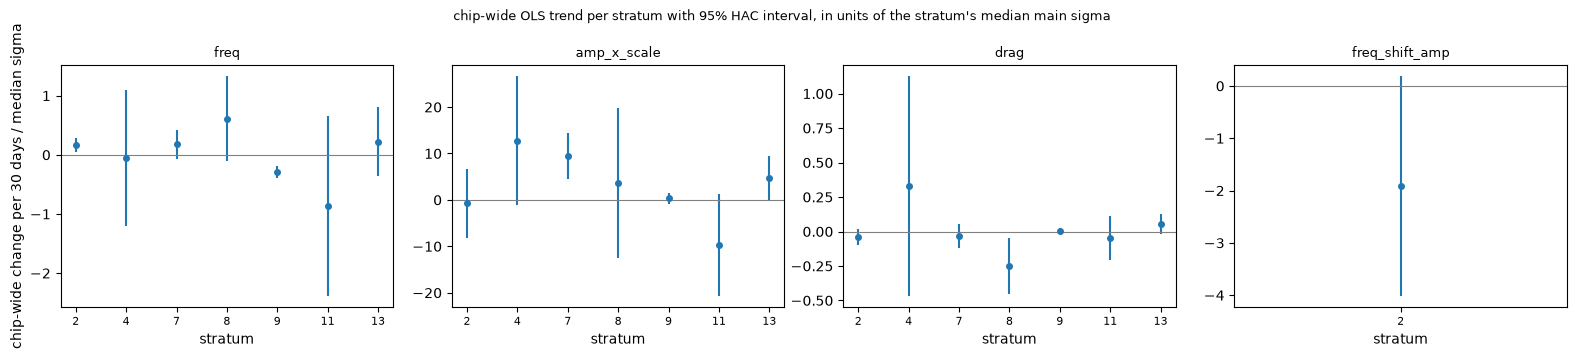

In [7]:
tr = methods.series_trends(d, SER, col="y").join(sers[["lstar"]], on=SER)
level = d.groupby(SER)["y"].agg(lambda s: s.abs().median()).groupby(["param", "stratum"]).median()
sig_st = sers.dropna(subset=["sigma_main"]).groupby(["param", "stratum"])["sigma_main"].median()


def rel(p: str, st: str, v: float) -> float:
    """Change relative to the level: a fraction for amp_x_scale (ln units), over the median |value| for drag and
    freq_shift_amp, none for freq."""
    if p == "amp_x_scale":
        return float(np.expm1(v))
    return v / level.get((p, st), np.nan) if p in ("drag", "freq_shift_amp") else np.nan


out = []
for (p, st), g in chip.groupby(["param", "stratum"]):
    if len(g) < MIN_N:
        continue
    r = methods.chip_trend(g["t"], g["y"], block[p])
    e = tr[(tr["param"] == p) & (tr["stratum"] == st)]
    e_l = e[e["lstar"].notna()]
    s = sig_st.get((p, st), np.nan)
    out.append({"param": p, "stratum": st, "runs": r["runs"], "blocks": r["blocks"], "per_30d": 30 * r["ts_slope"],
                "ols_per_30d": 30 * r["ols_slope"], "ci_lo": 30 * r["lo"], "ci_hi": 30 * r["hi"], "z": r["z"], "crit": r["crit"],
                "sigma_per_30d": 30 * r["ols_slope"] / s, "rel_per_30d": rel(p, st, 30 * r["ols_slope"]), "sigma": s,
                "qubits": len(e), "share_up": (e["ts_slope"] > 0).mean(), "qubits_lstar": len(e_l),
                "share_abs_z_gt_crit": (e_l["z"].abs() > e_l["crit"]).mean() if len(e_l) else np.nan})
dr = pd.DataFrame(out).set_index(["param", "stratum"]).sort_index(key=order)
dr["excludes_0"] = (dr["ci_lo"] > 0) | (dr["ci_hi"] < 0)
print("drift per param and stratum: the chip-wide series above, Theil-Sen and OLS change per 30 days (native: freq in Hz,",
      "amp_x_scale in ln units), OLS interval with the simulated critical value for its runs and bandwidth; sigma: over the",
      "stratum's median main sigma; rel: fraction for amp_x_scale, over the median |value| for drag and freq_shift_amp;",
      "per-qubit columns are descriptive:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(dr[["runs", "blocks", "per_30d", "ols_per_30d", "ci_lo", "ci_hi", "z", "crit", "excludes_0", "sigma_per_30d",
                "rel_per_30d", "qubits", "share_up", "qubits_lstar", "share_abs_z_gt_crit"]])

fig, axes = plt.subplots(1, len(PARAMS), figsize=(16, 3.6))
for axx, p in zip(axes, PARAMS):
    g = dr.xs(p).reset_index()
    x = np.arange(len(g))
    s = g["sigma"]
    axx.errorbar(x, g["sigma_per_30d"], yerr=[(g["ols_per_30d"] - g["ci_lo"]) / s, (g["ci_hi"] - g["ols_per_30d"]) / s], fmt="o", ms=4)
    axx.axhline(0, color="0.5", lw=0.8)
    axx.set_xticks(x, [s.split()[0] for s in g["stratum"]], fontsize=8)
    axx.set_title(p, fontsize=9)
    axx.set_xlabel("stratum")
axes[0].set_ylabel("chip-wide change per 30 days / median sigma")
fig.suptitle("chip-wide OLS trend per stratum with 95% HAC interval, in units of the stratum's median main sigma", fontsize=9)
fig.tight_layout()
out = FIG / "c2_drift.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- The interval excludes 0 for amp_x_scale strata 7 and 13 (+0.143% and +0.0873% per 30 days), freq strata 2 (+951 Hz) and 9 (−969 Hz), and drag stratum 8 (−0.25 σ).
- freq's drift is slow - 0.16 and −0.30 σ per 30 days - while amp_x_scale's is large in σ (9.5 in stratum 7) only because its σ is so small.
- Only stratum 9 of amp_x_scale and drag reaches 30 blocks (55.9), and neither shows drift.

## 4. Level steps at breaks

At each break, the step per qubit is the median of the $K$ runs after it minus the median of the $K$ before it (`methods.adjacent_steps`), with $K = \max(7, L_\text{var})$ - 14 runs for freq and 7 for the others. Steps are in the earlier stratum's main σ. Strata without a noise row drop out, so 2 → 4 spans stratum 3 (2025-02-12 to 02-17), 4 → 7 spans strata 5 and 6 (2025-03-18 to 03-28) and the thermal cycle is 9 → 11. The gating-era breaks 7 → 8 and 8 → 9 are the check.

A gap-matched placebo (`methods.placebo_steps`) puts the same window at random gaps inside strata, for both size and direction:

$$p = \frac{1 + \#\{\text{placebo} \ge \text{observed}\}}{1 + n_\text{placebo}}.$$

The bootstrap interval is descriptive, and placebo_z is the step in robust sd of the placebo.

step window K per param (runs): {'freq': 14, 'amp_x_scale': 7, 'drag': 7, 'freq_shift_amp': 7} | qubits needed: {'freq': 5, 'amp_x_scale': 5, 'drag': 5, 'freq_shift_amp': 3}


chip-wide level step between consecutive strata (median over qubits; z in the earlier stratum's main sigma, bootstrap interval over qubits, descriptive only). Placebo: within-stratum window steps spanning the boundary's median gap; placebo_p for |median z| (magnitude), direction_p for |share up - 0.5| (a common direction), both (1 + placebo values at least as large) / (1 + placebo values); q: Benjamini-Hochberg over the boundaries (p cannot fall below 1 / (1 + placebo_n)); placebo_z: step in robust sd of the placebo medians; beyond_own_q95: share of qubits whose |z| passes their own 95% placebo quantile (0.05 under no step):


qubits  gap_days  delta_native      z   z_lo  z_hi  share_up  placebo_n  placebo_p  placebo_q  placebo_z  direction_p  direction_q  beyond_own_q95 last_before first_after  \
param       stratum_before  stratum_after                                                                                                                                                                                 
amp_x_scale 2 (2024-09-18)  4 (2025-02-17)       23      12.9        0.0183    118   45.8   211     0.783        743    0.00134    0.00688       9.87        0.675            1           0.957  2025-02-04  2025-02-17   
                            7 (2025-03-28)        7        52       0.00911   35.3  -79.9   205     0.571        353     0.0226     0.0537       1.48        0.941            1               1  2025-02-04  2025-03-28   
            4 (2025-02-17)  7 (2025-03-28)       23      19.5      -0.00988  -86.4   -969  36.4     0.391        383     0.0026    0.00707      -7.53        0.875            1            0.87  2025-03-09  2025-03-28   
            7 (2025-03-28)  8 (2025-07-07)       31     0.543      -0.00204  -11.9  -16.9 -8.62    0.0968        694      0.247      0.522       -1.6         0.41            1           0.129  2025-07-06  2025-07-07   
            8 (2025-07-07)  9 (2025-08-22)       31     0.543     -0.000764  -5.02  -7.21 -1.42      0.29        770      0.498      0.631     -0.655        0.739            1          0.0323  2025-08-21  2025-08-22   
            9 (2025-08-22)  11 (2026-03-24)      30      26.5       -0.0119  -73.9   -457 -28.1     0.267        551    0.00181    0.00688       -6.2        0.696            1           0.833  2026-03-08  2026-04-04   
            11 (2026-03-24) 13 (2026-05-25)      30      5.02      8.97e-05  0.466  -1.75  1.77     0.533        833       0.95       0.95     0.0156        0.974            1             0.1  2026-05-20  2026-05-25   
drag        2 (2024-09-18)  4 (2025-02-17)       28      12.9      9.34e-11   7.83 -0.607  16.3     0.643        870    0.00115    0.00688       34.2        0.107            1            0.75  2025-02-04  2025-02-17   
            4 (2025-02-17)  7 (2025-03-28)       28      19.5      1.15e-11  0.185  -8.23  5.65       0.5        494      0.485      0.631      0.782            1            1           0.714  2025-03-09  2025-03-28   
            7 (2025-03-28)  8 (2025-07-07)       29     0.543     -2.64e-12 -0.224 -0.619 0.428     0.483        793      0.369      0.574     -0.847        0.948            1           0.103  2025-07-06  2025-07-07   
            8 (2025-07-07)  9 (2025-08-22)       29     0.543      8.24e-13 0.0792 -0.564 0.488     0.552        871      0.747      0.834      0.367        0.673            1           0.069  2025-08-21  2025-08-22   
            9 (2025-08-22)  11 (2026-03-24)      29      26.5      6.89e-11   3.73  -6.25  12.9     0.552        653    0.00153    0.00688       15.1        0.638            1           0.793  2026-03-08  2026-04-04   
            11 (2026-03-24) 13 (2026-05-25)      30      5.02     -2.13e-12 -0.155  -1.12 0.565       0.5        948      0.532      0.632     -0.575            1            1           0.267  2026-05-20  2026-05-25   
freq        2 (2024-09-18)  4 (2025-02-17)       28      12.9      2.91e+03  0.443 -0.769  2.02     0.536        791      0.326      0.574       1.05        0.797            1          0.0357  2025-02-04  2025-02-17   
            4 (2025-02-17)  7 (2025-03-28)       28      19.5     -1.44e+06   -390   -751   173     0.357        447    0.00223    0.00707       -801         0.27            1               1  2025-03-09  2025-03-28   
            7 (2025-03-28)  8 (2025-07-07)       29     0.543          -990 -0.235 -0.721 0.269     0.414        714      0.379      0.574     -0.989        0.429            1          0.0345  2025-07-06  2025-07-07   
            8 (2025-07-07)  9 (2025-08-22)       29     0.543          71.5 0.0223 -0.332 0.546     0.5

saved docs/figures/eda/c2_break_steps.png


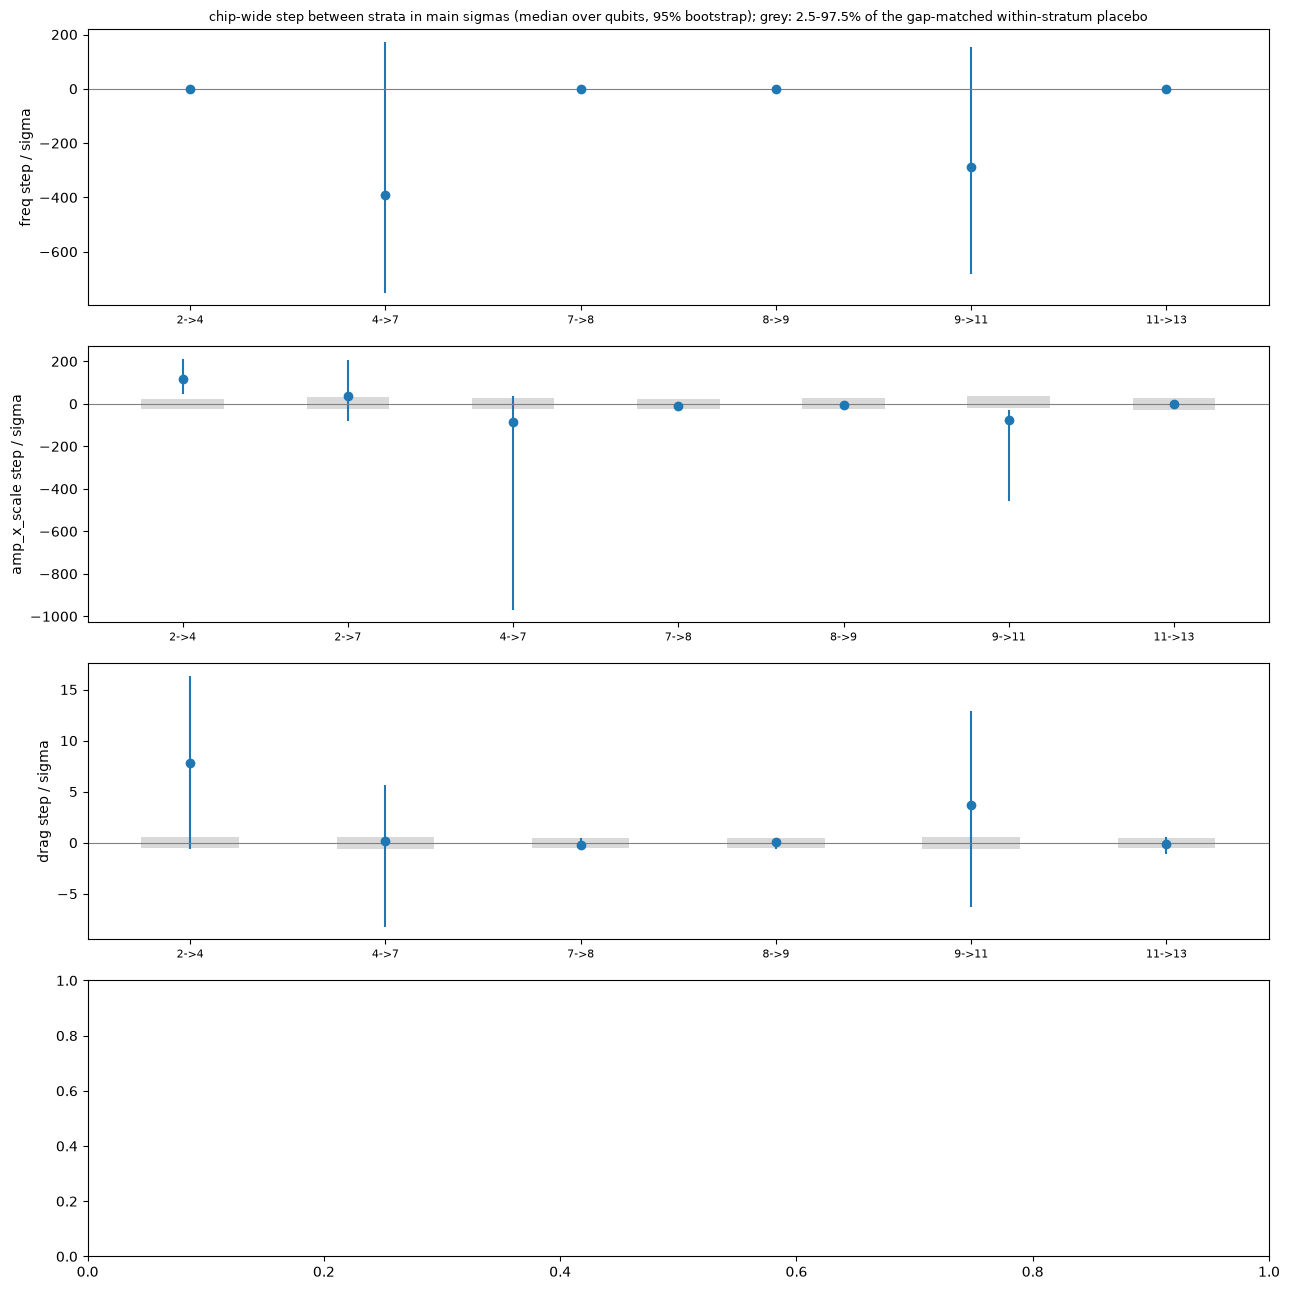

In [8]:
K = {p: int(max(K_MIN, lvar[p] if pd.notna(lvar.get(p, np.nan)) else max(LAGS))) for p in PARAMS}
print("step window K per param (runs):", K, "| qubits needed:", need)
dp = d[d["stratum"] != "settling"]
steps = pd.concat([methods.adjacent_steps(dp[dp["param"] == p], ["param", "qubit"], K[p], col="y") for p in PARAMS], ignore_index=True)
steps["sigma_before"] = sers["sigma_main"].reindex(pd.MultiIndex.from_frame(steps[["param", "qubit", "stratum_before"]])).to_numpy()
steps["z"] = steps["delta"] / steps["sigma_before"]
BND = ["param", "stratum_before", "stratum_after"]


def between(a: pd.Timestamp, b: pd.Timestamp) -> str:
    """Register entries in (a, b]: breaks by date and what, other events by type."""
    e = EV[(EV["at"] > a) & (EV["at"] <= b)]
    brk = e.loc[e["type"] == "BREAK", "label"].str.removeprefix("BREAK ").tolist()
    other = e.loc[e["type"] != "BREAK", "type"].value_counts().to_dict()
    return "; ".join(brk) + (f" | {other}" if other else "")


def placebo(p: str, gap: pd.Timedelta) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Within-stratum placebo for param p with the boundary's gap: per-qubit steps in main sigmas of their own series, and
    per split time the chip-wide median and share up (the needed qubits)."""
    pl = methods.placebo_steps(dp[dp["param"] == p], SER, K[p], col="y", gap=gap)
    pl["z"] = pl["step"] / sers["sigma_main"].reindex(pd.MultiIndex.from_frame(pl[SER])).to_numpy()
    pc = pl.groupby(["stratum", "t"])["z"].agg(median="median", up=lambda s: (s > 0).mean(), size="size")
    return pl, pc[pc["size"] >= need[p]]


out = []
for (p, sb, sa), g in steps.groupby(BND):
    if len(g) < need[p]:
        continue
    a, b, gap = g["t_before"].median(), g["t_after"].median(), (g["t_after"] - g["t_before"]).median()
    pl, pc = placebo(p, gap)
    med, lo, hi = methods.bootstrap_median(g["z"])
    up = (g["delta"] > 0).mean()
    q95 = pl.assign(a=pl["z"].abs()).groupby("qubit")["a"].quantile(0.95)
    has_q = g["qubit"].isin(q95.index)
    pl_lo, pl_hi = np.quantile(pc["median"], [0.025, 0.975]) if len(pc) else (np.nan, np.nan)
    out.append({"param": p, "stratum_before": sb, "stratum_after": sa, "qubits": len(g), "gap_days": gap / pd.Timedelta("1D"),
                "delta_native": g["delta"].median(), "z": med, "z_lo": lo, "z_hi": hi, "share_up": up, "placebo_n": len(pc),
                "placebo_p": methods.perm_p(pc["median"].abs(), abs(med)),
                "placebo_z": (med - pc["median"].median()) / methods.rsd(pc["median"]) if len(pc) >= 3 else np.nan,
                "direction_p": methods.perm_p((pc["up"] - 0.5).abs(), abs(up - 0.5)),
                "beyond_own_q95": float((g.loc[has_q, "z"].abs() > g.loc[has_q, "qubit"].map(q95)).mean()) if has_q.any() else np.nan,
                "pl_lo": pl_lo, "pl_hi": pl_hi, "last_before": a.strftime("%Y-%m-%d"), "first_after": b.strftime("%Y-%m-%d"),
                "between": between(a, b)})
bs = pd.DataFrame(out).set_index(BND).sort_index(
    key=lambda i: i.map(series.stratum_order) if i.name in ("stratum_before", "stratum_after") else i)
bs["placebo_q"] = methods.bh(bs["placebo_p"])
bs["direction_q"] = methods.bh(bs["direction_p"])
print("chip-wide level step between consecutive strata (median over qubits; z in the earlier stratum's main sigma, bootstrap",
      "interval over qubits, descriptive only). Placebo: within-stratum window steps spanning the boundary's median gap; placebo_p",
      "for |median z| (magnitude), direction_p for |share up - 0.5| (a common direction), both (1 + placebo values at least as",
      "large) / (1 + placebo values); q: Benjamini-Hochberg over the boundaries (p cannot fall below 1 / (1 + placebo_n));",
      "placebo_z: step in robust sd of the placebo medians; beyond_own_q95: share of qubits whose |z| passes their own 95%",
      "placebo quantile (0.05 under no step):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(bs[["qubits", "gap_days", "delta_native", "z", "z_lo", "z_hi", "share_up", "placebo_n", "placebo_p", "placebo_q", "placebo_z",
                "direction_p", "direction_q", "beyond_own_q95", "last_before", "first_after", "between"]])

fig, axes = plt.subplots(len(PARAMS), 1, figsize=(13, 13))
for axx, p in zip(axes, PARAMS):
    if p not in bs.index.get_level_values("param"):
        continue
    g = bs.xs(p).reset_index()
    x = np.arange(len(g))
    axx.bar(x, g["pl_hi"] - g["pl_lo"], bottom=g["pl_lo"], width=0.5, color="0.85", zorder=0)
    axx.errorbar(x, g["z"], yerr=[g["z"] - g["z_lo"], g["z_hi"] - g["z"]], fmt="o")
    axx.axhline(0, color="0.5", lw=0.8)
    axx.set_xticks(x, [f"{a.split()[0]}->{b.split()[0]}" for a, b in zip(g["stratum_before"], g["stratum_after"])], fontsize=8)
    axx.set_ylabel(f"{p} step / sigma")
axes[0].set_title("chip-wide step between strata in main sigmas (median over qubits, 95% bootstrap); grey: 2.5-97.5% of the gap-matched within-stratum placebo", fontsize=9)
fig.tight_layout()
out = FIG / "c2_break_steps.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- freq steps at 4 → 7 by −1.44 MHz (−390 σ, with all 28 qubits beyond their own placebo) and at the thermal cycle by −975 kHz (−288 σ, 0.929 beyond). Both have $q$ 0.007.
- amp_x_scale steps at the same two boundaries (−86 and −74 σ) and at 2 → 4 (+118 σ, 0.783 of qubits up), and drag at 2 → 4 (+7.83 σ) and the thermal cycle (+3.73 σ). All have $q$ 0.007, with 0.75 to 0.96 of qubits beyond their own placebo, but the intervals are wide.
- The gating-era breaks have $p$ 0.25 to 0.92, and direction_q is 1 everywhere.

A boundary step only says the level differs between the two windows - not when it changed. For steps with $p \le 0.05$ we follow the chip-wide level run by run across the windows, in every stratum. Per run it's the median over qubits of the raw value minus the qubit's before-window median, as a share of the step. A step that happens at one run shows up as one change near 1, with the rest small.

In [9]:
P_MAX = 0.05  # boundaries whose placebo_p is at most this get localised
keep = allr[~drop].sort_values("t")
run_t = keep.groupby("run")["t"].min()
out = []
for (p, sb, sa), r in bs[bs["placebo_p"] <= P_MAX].iterrows():
    g = steps[(steps["param"] == p) & (steps["stratum_before"] == sb) & (steps["stratum_after"] == sa)]
    x = keep[(keep["param"] == p) & keep["qubit"].isin(g["qubit"])]
    base, w0, w1 = {}, [], []
    for q, tb, ta in zip(g["qubit"], g["t_before"], g["t_after"]):
        xq = x[x["qubit"] == q]
        pre, post = xq[xq["t"] <= tb].tail(K[p]), xq[xq["t"] >= ta].head(K[p])
        base[q] = pre["value"].median()
        w0.append(pre["t"].min())
        w1.append(post["t"].max())
    w = x[(x["t"] >= min(w0)) & (x["t"] <= max(w1))]
    lvl = (w["value"] - w["qubit"].map(base)).groupby(w["run"]).agg(["median", "size"])
    frac = lvl.loc[lvl["size"] >= need[p], "median"] / r["delta_native"]
    jump = frac.diff().dropna()
    top = jump.abs().idxmax()
    prev = frac.index[frac.index.get_loc(top) - 1]
    out.append({"param": p, "stratum_before": sb, "stratum_after": sa, "runs": len(frac), "from": run_t[prev], "to": run_t[top],
                "share": jump[top], "next_largest": jump.drop(top).abs().max(), "between": between(run_t[prev], run_t[top])})
loc = pd.DataFrame(out).set_index(BND)
print(f"where each boundary step with placebo_p <= {P_MAX} happens: from the first run of the before windows to the last of the",
      "after windows, every run (any stratum, incidents and f01 flags out) with the needed qubits; per run the chip-wide median of",
      "value - the qubit's before-window median, as a share of the boundary step. The largest run-to-run change (from -> to), its",
      "share, the next largest |share|, and the register entries between the two runs:")
with pd.option_context("display.float_format", "{:.3g}".format, "display.max_colwidth", 140):
    display(loc.assign(**{c: loc[c].dt.strftime("%Y-%m-%d %H:%M") for c in ["from", "to"]}))

where each boundary step with placebo_p <= 0.05 happens: from the first run of the before windows to the last of the after windows, every run (any stratum, incidents and f01 flags out) with the needed qubits; per run the chip-wide median of value - the qubit's before-window median, as a share of the boundary step. The largest run-to-run change (from -> to), its share, the next largest |share|, and the register entries between the two runs:


runs              from                to  share  next_largest                                                                                                                                      between
param       stratum_before stratum_after                                                                                                                                                                                                              
amp_x_scale 2 (2024-09-18) 4 (2025-02-17)     26  2025-02-04 19:45  2025-02-12 13:41   1.36         0.428                                                         2025-02-12 outage ends (hand-written DS2 values) | {'OUTAGE': 2, 'UNTRACKED_DS2': 1}
                           7 (2025-03-28)     86  2025-02-04 19:45  2025-02-12 13:41   2.83          2.17                                                         2025-02-12 outage ends (hand-written DS2 values) | {'OUTAGE': 2, 'UNTRACKED_DS2': 1}
            4 (2025-02-17) 7 (2025-03-28)     35  2025-03-09 08:00  2025-03-19 08:00   1.88         0.794                                                         2025-03-18 outage ends (hand-written DS2 values) | {'OUTAGE': 2, 'UNTRACKED_DS2': 2}
            9 (2025-08-22) 11 (2026-03-24)    33  2026-03-08 19:42  2026-03-24 14:45  0.922         0.467  2026-03-22 thermal cycle ends (f01 level shift); 2026-03-24 couplings 1-10 and 1-2 reverse | {'THERMAL_CYCLE': 2, 'INCIDENT': 2, 'F01_FL...
drag        2 (2024-09-18) 4 (2025-02-17)     26  2025-02-16 19:45  2025-02-17 08:00  -1.02         0.874                                                                                                                                             
            9 (2025-08-22) 11 (2026-03-24)    33  2026-03-29 19:43  2026-03-30 08:45   1.67          1.57                                                                                                                                             
freq        4 (2025-02-17) 7 (2025-03-28)     99  2025-03-09 08:00  2025-03-19 08:00  0.863          0.15                                                         2025-03-18 outage ends (hand-written DS2 values) | {'OUTAGE': 2, 'UNTRACKED_DS2': 2}
            9 (2025-08-22) 11 (2026-03-24)    45  2026-03-08 19:42  2026-03-24 14:45  0.968          0.24  2026-03-22 thermal cycle ends (f01 level shift); 2026-03-24 couplings 1-10 and 1-2 reverse | {'THERMAL_CYCLE': 2, 'INCIDENT': 2, 'F01_FL...

**Results.**

- freq 4 → 7: 0.86 of the step falls between 2025-03-09 08:00 and 2025-03-19 08:00. That's across the 10-day outage that ends at the 2025-03-18 break, with untracked DS2 writes in between.
- At the thermal cycle 0.97 of the step falls between 2026-03-08 and 03-24, and no other change is above 0.24.
- amp_x_scale steps in the same two gaps, less cleanly (next largest 0.79 and 0.47). Its 2 → 4 step falls between 2025-02-04 and the 2025-02-12 outage end (next largest 0.43).
- drag doesn't localise - its largest change is 1.67 against 1.57 at the thermal cycle and −1.02 against 0.87 at 2 → 4. So drag's boundary steps are a wandering level, not a step.

So freq's 4 → 7 step and amp_x_scale's 2 → 4 step belong to the outages, not to the calibrate_1q code changes on 2025-02-17, 03-20 and 03-28. D1b section 9 follows the DS2 writes behind them.

## 5. Change points

As in C1 section 5, we look for level shifts inside strata with `methods.binary_segmentation`, which splits a series where the CUSUM statistic

$$T = \frac{\max_k |S_k|}{\hat\sigma_\text{LR}\sqrt{n}}$$

beats its simulated critical value (`methods.cusum_crit`). The block-28 params - freq and freq_shift_amp - get the jump scan (`methods.scan_jumps`) instead. The minimum segment is $\max(7, L^*)$ per qubit and $K$ chip-wide, and a split at the first or last allowed position is an *edge*. We match change points to the register within 2 days, against chance.

In [10]:
de = d[d["lstar"].notna()]
cp, elig = methods.change_points(de, SER, col="y", scan_col="scan")
cp = cp.join(sers["sigma_main"], on=SER)
cp["shift_sigma"] = cp["shift"] / cp["sigma_main"]
cp["near"] = methods.near(cp["t"], EV["at"], NEAR_EVENT)
elig["near"] = methods.near(elig["t"], EV["at"], NEAR_EVENT)
print("per-series change points (CUSUM against its simulated critical value where the param's variance ratio levels off,",
      "else the jump scan); edge: at the first or last allowed split of the series; matched within 2 days against chance:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(elig.groupby("param").agg(series=("qubit", lambda s: len(elig.loc[s.index, SER].drop_duplicates())), chance=("near", "mean"))
            .join(cp.groupby("param").agg(change_points=("t", "size"), method=("method", "first"), edge=("edge", "sum"),
                                          series_with=("qubit", lambda s: len(cp.loc[s.index, SER].drop_duplicates())),
                                          matched=("near", "mean"), median_abs_shift_sigma=("shift_sigma", lambda s: s.abs().median())))
            .assign(matched_over_chance=lambda x: x["matched"] / x["chance"]).reindex(PARAMS))
bt = []
for ty in sorted(EV["type"].unique()):
    at = EV.loc[EV["type"] == ty, "at"]
    m = pd.Series(methods.near(cp["t"], at, NEAR_EVENT), index=cp.index).groupby(cp["param"]).agg(["sum", "mean"])
    c = pd.Series(methods.near(elig["t"], at, NEAR_EVENT), index=elig.index).groupby(elig["param"]).mean()
    bt.append(m.join(c.rename("chance"), how="outer").assign(event_type=ty))
bt = pd.concat(bt).rename(columns={"sum": "change_points", "mean": "matched"}).reset_index().set_index(["param", "event_type"])
bt = bt[(bt["change_points"] > 0) | (bt["chance"] > 0)].assign(matched_over_chance=lambda x: x["matched"] / x["chance"])
print("by event type:")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(bt)

per-series change points (CUSUM against its simulated critical value where the param's variance ratio levels off, else the jump scan); edge: at the first or last allowed split of the series; matched within 2 days against chance:


,series,chance,change_points,method,edge,series_with,matched,median_abs_shift_sigma,matched_over_chance
param,,,,,,,,,
freq,142,0.0558,192,scan,16,79,0.0625,15.6,1.12
amp_x_scale,207,0.0612,158,cusum,6,104,0.0253,17.1,0.414
drag,145,0.057,59,cusum,2,34,0.0339,2.96,0.595
freq_shift_amp,12,0.0467,8,scan,2,3,0,27.6,0


by event type:


,,change_points,matched,chance,matched_over_chance
param,event_type,,,,
amp_x_scale,DS4_GAP,4,0.0253,0.0214,1.18
drag,DS4_GAP,1,0.0169,0.0226,0.75
freq,DS4_GAP,7,0.0365,0.0212,1.72
freq_shift_amp,DS4_GAP,0,0,0.0102,0
amp_x_scale,F01_FLAG,0,0,0.015,0
drag,F01_FLAG,1,0.0169,0.0146,1.16
freq,F01_FLAG,5,0.026,0.0168,1.55
freq_shift_amp,F01_FLAG,0,0,0.0127,0
amp_x_scale,INCIDENT,0,0,0.00857,0


**Results.**

- Per series, change points match the register at 0.41 (amp_x_scale) to 1.12 (freq) times chance, with median shifts of 3 (drag) to 28 σ.
- `OUTAGE` and `UNTRACKED_DS2_OTHER` can't be tested, since they sit at or next to breaks and no segment crosses one. The other event types match at 0.73 to 1.86 times chance, on 1 to 7 change points each.

Then the same search on the chip-wide series of section 3.

chip-wide series: runs per param: {'amp_x_scale': 1035, 'drag': 1172, 'freq': 1177, 'freq_shift_amp': 191} | minimum segment K: {'freq': 14, 'amp_x_scale': 7, 'drag': 7, 'freq_shift_amp': 7}
chip-wide change points (first run after the split; method, statistic and its critical value; shift native and in the stratum's median main sigma; edge; register events within 2 days):


,param,stratum,t,method,stat,crit,shift,shift_sigma,edge,event
0,amp_x_scale,7 (2025-03-28),2025-05-31 08:45,cusum,3.08,1.44,0.00372,24.7,False,
1,amp_x_scale,7 (2025-03-28),2025-06-26 08:45,cusum,2.73,1.7,-0.00333,-22.1,False,
2,amp_x_scale,11 (2026-03-24),2026-04-14 19:46,cusum,2.4,1.64,-0.00245,-14.4,False,
3,amp_x_scale,13 (2026-05-25),2026-06-24 19:40,cusum,1.86,1.51,0.0019,10.4,False,
4,drag,13 (2026-05-25),2026-07-11 08:45,cusum,1.63,1.51,4.29e-12,0.177,False,
5,freq,13 (2026-05-25),2026-08-10 07:45,scan,5.43,4.47,8.78e+03,2.05,False,
6,freq_shift_amp,2 (2024-09-18),2024-10-21 21:18,scan,9.73,4.33,-0.00224,-9.62,True,
7,freq_shift_amp,2 (2024-09-18),2024-10-31 08:00,scan,4.98,4.33,0.00114,4.92,False,
8,freq_shift_amp,2 (2024-09-18),2024-11-06 18:26,scan,6.61,4.33,-0.00152,-6.53,False,


matched share against chance:


,size,mean,chance
param,,,
amp_x_scale,4,0,0.0636
drag,1,0,0.0555
freq,1,0,0.0547
freq_shift_amp,3,0,0


saved docs/figures/eda/c2_chip_series.png


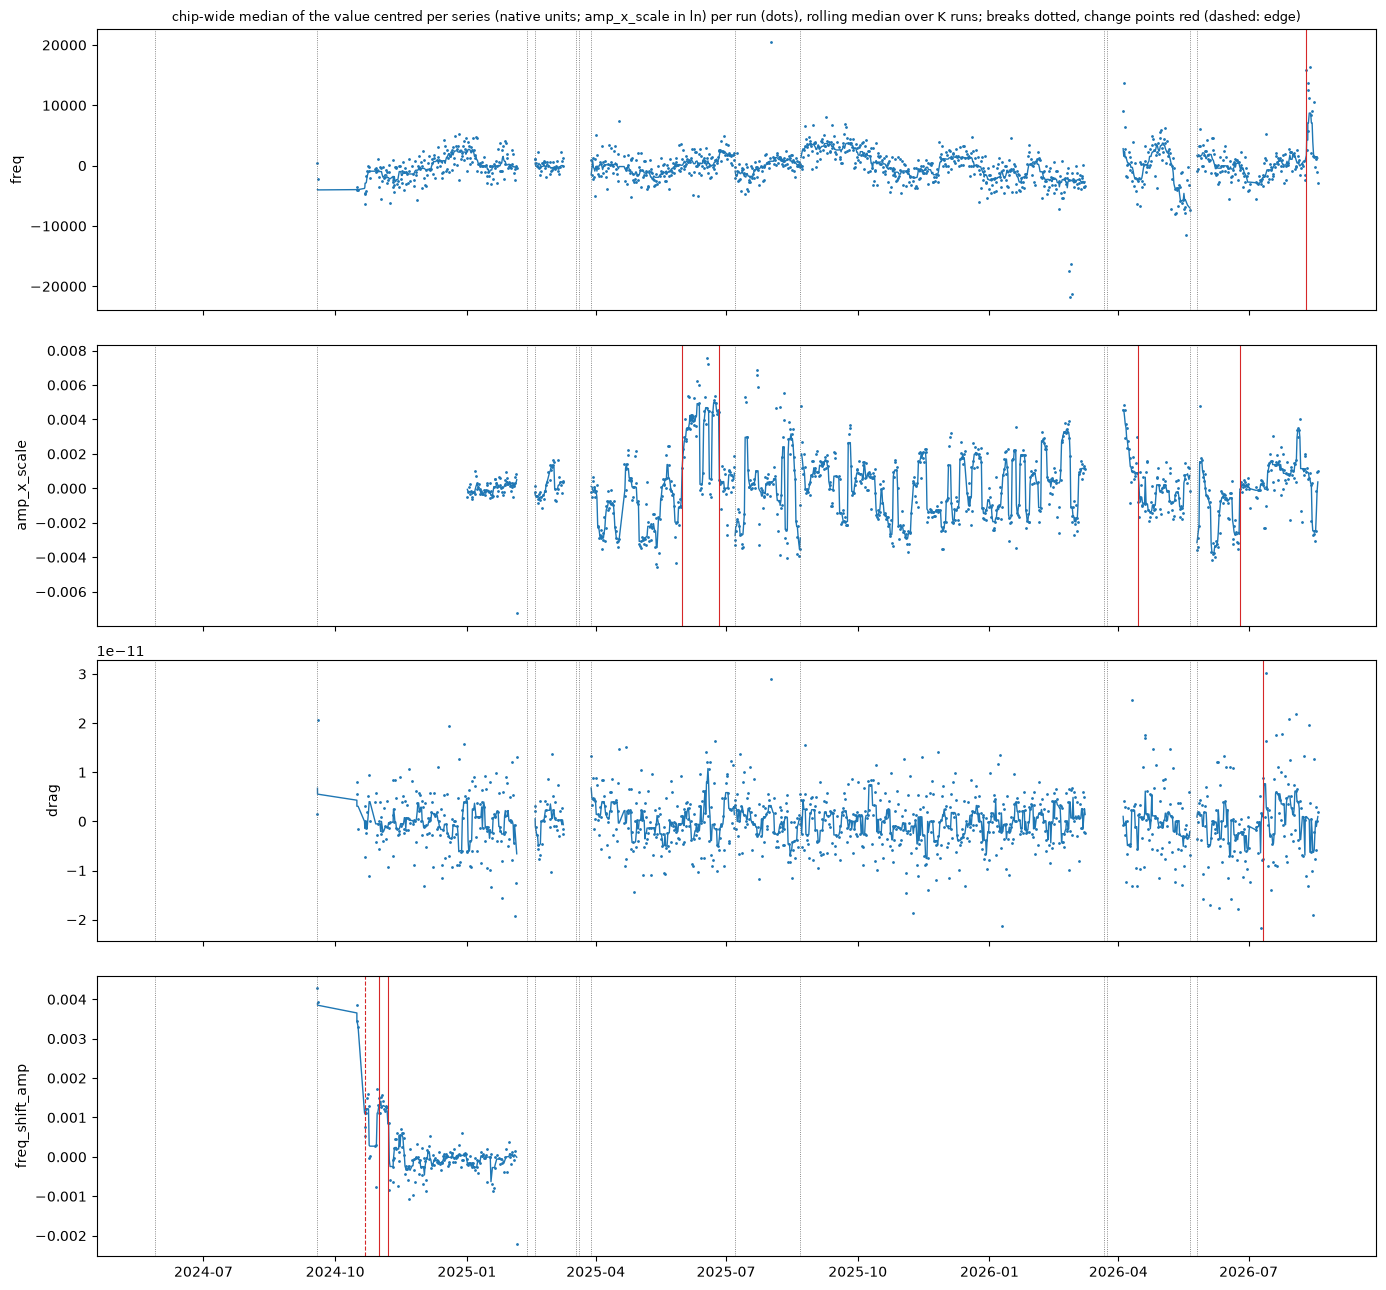

In [11]:
chip["block"] = chip["param"].map(block)  # chip: the section 3 chip-wide series (value centred per series, native units)
chip["min_seg"] = chip["param"].map(K)
chip["scan"] = ~chip["param"].map(plateau)
ccp, celig = methods.change_points(chip, ["param", "stratum"], col="y", scan_col="scan")
ccp["shift_sigma"] = ccp["shift"] / sig_st.reindex(pd.MultiIndex.from_frame(ccp[["param", "stratum"]])).to_numpy()
ccp["near"] = methods.near(ccp["t"], EV["at"], NEAR_EVENT)
ccp["event"] = ["; ".join(EV.loc[(EV["at"] - t).abs() <= NEAR_EVENT, "label"]) for t in ccp["t"]]
celig["near"] = methods.near(celig["t"], EV["at"], NEAR_EVENT)
print("chip-wide series: runs per param:", chip.groupby("param").size().to_dict(), "| minimum segment K:", K)
print("chip-wide change points (first run after the split; method, statistic and its critical value; shift native and in the",
      "stratum's median main sigma; edge; register events within 2 days):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(ccp.sort_values(["param", "t"]).assign(t=lambda x: x["t"].dt.strftime("%Y-%m-%d %H:%M"))
            [["param", "stratum", "t", "method", "stat", "crit", "shift", "shift_sigma", "edge", "event"]].reset_index(drop=True))
    print("matched share against chance:")
    display(ccp.groupby("param")["near"].agg(["size", "mean"]).join(celig.groupby("param")["near"].mean().rename("chance")))

fig, axes = plt.subplots(len(PARAMS), 1, figsize=(14, 13), sharex=True)
for axx, p in zip(axes, PARAMS):
    g = chip[chip["param"] == p]
    for _, s in g.groupby("stratum"):
        axx.plot(s["t"], s["y"], ".", ms=2, color="C0")
        axx.plot(s["t"], s["y"].rolling(K[p], center=True, min_periods=3).median(), color="C0", lw=1)
    for b in periods.BREAKS:
        axx.axvline(b.at, color="0.4", lw=0.6, ls=":")
    for t, e in zip(ccp.loc[ccp["param"] == p, "t"], ccp.loc[ccp["param"] == p, "edge"]):
        axx.axvline(t, color="C3", lw=0.8, ls="--" if e else "-")
    axx.set_ylabel(p)
axes[0].set_title("chip-wide median of the value centred per series (native units; amp_x_scale in ln) per run (dots), rolling median over K runs; breaks dotted, change points red (dashed: edge)", fontsize=9)
fig.tight_layout()
out = FIG / "c2_chip_series.png"
fig.savefig(out, dpi=120)
print("saved", out.relative_to(REPO_ROOT))

**Results.**

- amp_x_scale steps on 2025-05-31, 06-26, 2026-04-14 and 06-24 (10 to 25 σ), with no event near.
- drag has only 2026-07-11 (0.18 σ), freq only 2026-08-10 (+8.78 kHz, 2.05 σ), and freq_shift_amp has three in late 2024 (one at an edge), none near an event.

To see whether the section 3 drift is a slope or a stack of these steps, we refit each stratum whose interval excludes 0 between its change points, and the whole stratum with bandwidth 28.

In [12]:
out = []
for p, st in dr.index[dr["excludes_0"]]:
    g = chip[(chip["param"] == p) & (chip["stratum"] == st)].sort_values("t")
    at = sorted(ccp.loc[(ccp["param"] == p) & (ccp["stratum"] == st), "t"])
    parts = [("whole", g, block[p])] + ([("whole, bandwidth 28", g, 28)] if block[p] < 28 else [])
    edges = [g["t"].min(), *at, g["t"].max() + pd.Timedelta("1s")]
    parts += [(f"from {a:%Y-%m-%d}", g[(g["t"] >= a) & (g["t"] < b)], block[p]) for a, b in zip(edges[:-1], edges[1:])] if at else []
    for name, s, bw in parts:
        r = methods.chip_trend(s["t"], s["y"], bw) if len(s) >= MIN_N else None
        out.append({"param": p, "stratum": st, "part": name, "runs": len(s), "bandwidth": bw,
                    **({"ols_per_30d": 30 * r["ols_slope"], "ci_lo": 30 * r["lo"], "ci_hi": 30 * r["hi"]} if r else {})})
seg = pd.DataFrame(out)
seg["excludes_0"] = (seg["ci_lo"] > 0) | (seg["ci_hi"] < 0)
print("chip-wide drift (as section 3, native units per 30 days) of every param-stratum whose interval excludes 0: the whole",
      f"stratum (also with bandwidth 28 where the block is shorter), and each part between its chip-wide change points ({MIN_N}+ runs):")
with pd.option_context("display.float_format", "{:.3g}".format):
    display(seg.set_index(["param", "stratum", "part"]))

chip-wide drift (as section 3, native units per 30 days) of every param-stratum whose interval excludes 0: the whole stratum (also with bandwidth 28 where the block is shorter), and each part between its chip-wide change points (20+ runs):


runs  bandwidth  ols_per_30d     ci_lo     ci_hi  excludes_0
param       stratum         part                                                                             
amp_x_scale 7 (2025-03-28)  whole                 195          7      0.00143  0.000683   0.00218        True
                            whole, bandwidth 28   195         28      0.00143  0.000267   0.00259        True
                            from 2025-03-28       121          7     0.000136  -0.00093    0.0012       False
                            from 2025-05-31        52          7     0.000876  -0.00242   0.00417       False
                            from 2025-06-26        22          7      0.00241  -0.00311   0.00794       False
            13 (2026-05-25) whole                 158          7     0.000873  5.76e-06   0.00174        True
                            whole, bandwidth 28   158         28     0.000873 -0.000164   0.00191       False
                            from 2026-05-25        59          7     -0.00179  -0.00528    0.0017       False
                            from 2026-06-24        99          7     9.41e-05  -0.00127   0.00146       False
drag        8 (2025-07-07)  whole                  92          7    -3.42e-12 -6.15e-12 -6.83e-13        True
                            whole, bandwidth 28    92         28    -3.42e-12 -6.07e-12 -7.68e-13        True
freq        2 (2024-09-18)  whole                 209         28          951       290  1.61e+03        True
            9 (2025-08-22)  whole                 391         28         -969 -1.31e+03      -627        True

**Results.**

- For amp_x_scale no part between change points excludes 0 in strata 7 or 13, and with bandwidth 28 stratum 13 includes 0 too.
- freq strata 2 and 9 and drag stratum 8 have no change point to split at, so their drift stands, but it's slow (freq 0.16 and 0.30 σ per 30 days).

So amp_x_scale moves in steps within a stratum, while freq has a slow drift on top of its two large steps.

## Conclusion

| Result | Status |
|---|---|
| The centred σ is 1.46, 1.19 and 1.02 times the fit sd | We read signal off the centred σ, with the fit sd as the high end |
| amp_x_scale is −3.86 σ in the evening; freq and drag have no time-of-day level | Shift evening rows |
| freq $c$ 1.23, $L_\text{var}$ 14, $\tau$ 19.1 days; against the fit sd $L_\text{var}$ is 1 | freq's lag-1 signal depends on the σ - use lags of a week or more |
| drag $c$ 1.73, $\tau$ 1.34 days; amp_x_scale $\tau$ 3.2 days | Per-qubit tests only on series with an $L^*$ |
| Common mode for amp_x_scale everywhere, freq in strata 4, 9 and 11, drag nowhere | Chip-wide series with runs as the sample |
| freq −1.44 MHz across the 2025-03 outage and −975 kHz at the thermal cycle, each at one run | The outage, not the code changes - D1b section 9 |
| amp_x_scale steps in the same gaps and across the 2025-02 outage; drag doesn't localise | drag's boundary steps are a wandering level |
| 4 amp_x_scale steps within strata, with no event | Phase 02 looks for a cause |
| amp_x_scale's drift goes away between change points; freq and drag keep theirs, at most 0.3 σ per 30 days | Model amp_x_scale as levels; freq's drift is slow |
| Per-series change points match the register at 0.4 to 1.1 times chance | Don't read them one by one |